In [21]:
# Problem 1-d

import numpy as np
import statsmodels.api as sm
import pandas as pd
from tabulate import tabulate

# Set random seed for reproducibility
np.random.seed(42)

# Define a function to run the simulation
def run_simulation(n):
  # True model parameters
  a = 1
  b = 2
  c = 3

  # Stimulate predictors
  X = np.random.normal(0,10,n)
  Z = 0.7 * X + np.random.normal(0,10,n) * 0.5 # Z is correlated with X

  # Stimulate independent error
  e = np.random.normal(0,10,n)

  # Generate outcome variable Y
  Y = a + b*X + c*Z + e

  # Full model: Y ~ X Z
  X_full = sm.add_constant(np.column_stack((X, Z)))
  model_full = sm.OLS(Y, X_full).fit()

  # Misspecified model Y ~ X and omitting Z
  X_partial = sm.add_constant(X)
  model_partial = sm.OLS(Y, X_partial).fit()

  # Return estimates
  return {
    "Sample Size": n,
    "True β (X)": b,
    "Estimated β (Full Model)": model_full.params[1],
    "Estimated β (Omitting Z)": model_partial.params[1],
    "SE (Full Model)": model_full.bse[1],
    "SE (Omitting Z)": model_partial.bse[1]
}

# Run the simulation with small and large sample sizes
results_small = run_simulation(n=100)
results_large = run_simulation(n=10000)

# Compile results into a DataFrame
results_df = pd.DataFrame([results_small, results_large], index=["n=100", "n=10000"])

# Display results
print(tabulate(results_df, headers='keys', tablefmt='grid', floatfmt=".3f"))

+---------+---------------+--------------+----------------------------+----------------------------+-------------------+-------------------+
|         |   Sample Size |   True β (X) |   Estimated β (Full Model) |   Estimated β (Omitting Z) |   SE (Full Model) |   SE (Omitting Z) |
+=========+===============+==============+============================+============================+===================+===================+
| n=100   |       100.000 |        2.000 |                      2.243 |                      4.113 |             0.187 |             0.196 |
+---------+---------------+--------------+----------------------------+----------------------------+-------------------+-------------------+
| n=10000 |     10000.000 |        2.000 |                      1.993 |                      4.119 |             0.017 |             0.018 |
+---------+---------------+--------------+----------------------------+----------------------------+-------------------+-------------------+


           Model  Estimated Intercept  Estimated Slope  R-squared
0     Clean Data             2.007428         4.856743   0.956134
1  With Outliers             3.907978         5.825004   0.212928


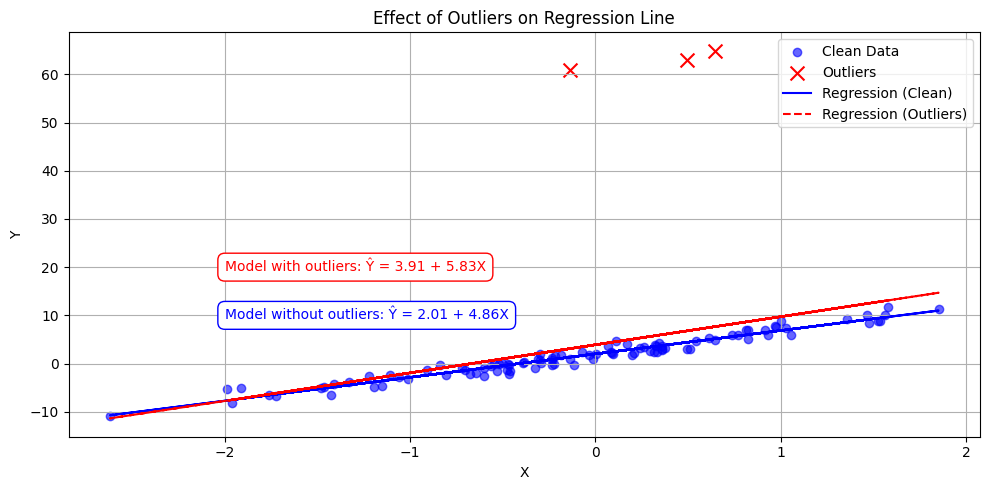

In [22]:
# Problem 2-b

import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

# Step 1: Simulate clean data
n = 100
X = np.random.normal(0, 1, n)
epsilon = np.random.normal(0, 1, n)
Y_clean = 2 + 5 * X + epsilon

# Step 2: Add outliers to Y
Y_outliers = Y_clean.copy()
Y_outliers[:3] += 60  # Add large positive outliers

# Step 3: Estimate models
X_const = sm.add_constant(X)
model_clean = sm.OLS(Y_clean, X_const).fit()
model_outliers = sm.OLS(Y_outliers, X_const).fit()

# Print comparison
results = pd.DataFrame({
    "Model": ["Clean Data", "With Outliers"],
    "Estimated Intercept": [model_clean.params[0], model_outliers.params[0]],
    "Estimated Slope": [model_clean.params[1], model_outliers.params[1]],
    "R-squared": [model_clean.rsquared, model_outliers.rsquared]
})
print(results)

# Plot
plt.figure(figsize=(10, 5))
plt.scatter(X, Y_clean, label="Clean Data", color="blue", alpha=0.6)
plt.scatter(X[:3], Y_outliers[:3], label="Outliers", color="red", marker="x", s=100)
plt.plot(X, model_clean.predict(X_const), label="Regression (Clean)", color="blue")
plt.plot(X, model_outliers.predict(X_const), label="Regression (Outliers)", color="red", linestyle="--")

# Add regression equations to the plot
eq_clean = f"Model without outliers: Ŷ = {model_clean.params[0]:.2f} + {model_clean.params[1]:.2f}X"
eq_outliers = f"Model with outliers: Ŷ = {model_outliers.params[0]:.2f} + {model_outliers.params[1]:.2f}X"

plt.text(-2, min(Y_clean) + 20, eq_clean, color="blue", fontsize=10, bbox=dict(facecolor='white', edgecolor='blue', boxstyle='round,pad=0.5'))
plt.text(-2, min(Y_clean) + 30, eq_outliers, color="red", fontsize=10, bbox=dict(facecolor='white', edgecolor='red', boxstyle='round,pad=0.5'))

# Final touches
plt.legend()
plt.title("Effect of Outliers on Regression Line")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:
# Problem 3

from google.colab import files
uploaded = files.upload()


Saving FE-GWP1_model_selecxtion_1.csv to FE-GWP1_model_selecxtion_1 (1).csv


In [24]:
data_set = pd.read_csv('FE-GWP1_model_selecxtion_1.csv')
data_set.head()

,Y,X1,X2,X3,X4,X5
0,3.388410,0.017954,-0.800583,-0.352454,2.187210,1.014887
1,0.287191,0.083057,-0.597947,-0.357639,-1.630284,0.221841
2,3.989645,-0.923437,-1.386575,1.180202,0.632606,-1.576638
3,-2.959602,-0.313775,2.955133,-1.798692,-2.117621,0.159291
4,0.529773,0.388996,1.019611,0.472062,0.590497,0.877048


In [25]:
# OLS model ------------------------
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.api as sms

model_ols = smf.ols("Y ~ X1 + X2 + X3 + X4 + X5", data=data_set).fit()
print(model_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.630
Method:                 Least Squares   F-statistic:                     34.74
Date:                Sat, 14 Jun 2025   Prob (F-statistic):           5.83e-20
Time:                        11:28:16   Log-Likelihood:                -125.30
No. Observations:                 100   AIC:                             262.6
Df Residuals:                      94   BIC:                             278.2
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.1902      0.090     13.246      0.0

In [26]:
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, acorr_ljungbox
from statsmodels.stats.outliers_influence import variance_inflation_factor
# Build independent variables
X = data_set[['X1', 'X2', 'X3', 'X4', 'X5']]
X = sm.add_constant(X)

# Caculate VIF
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print("\n--- VIF ---")
print(vif_data)

# Autocorrelation test
# Durbin_watson test
dw_stat = durbin_watson(model_ols.resid)
print(f"\nDurbin-Watson statistic: {dw_stat:.4f}")

if abs(dw_stat - 2) <= 0.2:
    print("=> No significant autocorrelation (very good).")
elif dw_stat < 1.5:
    print("=> Possible positive autocorrelation.")
elif dw_stat > 2.5:
    print("=> Possible negative autocorrelation.")
else:
    print("=> Slight autocorrelation may be present.")


# Breusch-Godfrey Test
bg_stat = acorr_breusch_godfrey(model_ols, nlags=1)
print("\n--- Breusch-Godfrey Test ---")
print(f"LM Statistic: {bg_stat[0]:.4f}")
print(f"p-value: {bg_stat[1]:.4f}")

if bg_stat[1] > 0.05:
    print("=> No autocorrelation (residuals are independent).")
else:
    print("=> Autocorrelation detected (model needs improvement).")

# Ljung-Box Test
ljung_box = acorr_ljungbox(model_ols.resid, lags=[10], return_df=True)
print("\n--- Ljung-Box Test (lag=10) ---")
print(ljung_box)

if ljung_box["lb_pvalue"].iloc[0] > 0.05:
    print("=> No higher-order autocorrelation (residuals resemble white noise).")
else:
    print("=> Higher-order autocorrelation detected (model may need refinement).")


--- VIF ---
  Variable       VIF
0    const  1.057648
1       X1  1.023092
2       X2  1.016781
3       X3  1.048643
4       X4  1.021681
5       X5  1.057760

Durbin-Watson statistic: 1.9695
=> No significant autocorrelation (very good).

--- Breusch-Godfrey Test ---
LM Statistic: 0.0159
p-value: 0.8996
=> No autocorrelation (residuals are independent).

--- Ljung-Box Test (lag=10) ---
      lb_stat  lb_pvalue
10  10.464276   0.400747
=> No higher-order autocorrelation (residuals resemble white noise).


In [27]:
from statsmodels.stats.diagnostic import het_breuschpagan
# Perform Breusch-Pagan test for heteroskedasticity
residuals = model_ols.resid
exog = model_ols.model.exog

bp_test = het_breuschpagan(residuals, exog)
bp_labels = ['LM Statistic', 'LM-Test p-value', 'F-Statistic', 'F-Test p-value']
bp_results = dict(zip(bp_labels, bp_test))

print("\nBreusch-Pagan test results:")
for k, v in bp_results.items():
    print(f"{k}: {v:.4f}")

# Conclusion based on p-value
if bp_results['F-Test p-value'] < 0.05:
    print("\nConclusion: The model shows evidence of heteroskedasticity (p < 0.05).")
else:
    print("\nConclusion: No evidence of heteroskedasticity was found (p ≥ 0.05).")


Breusch-Pagan test results:
LM Statistic: 2.9747
LM-Test p-value: 0.7039
F-Statistic: 0.5764
F-Test p-value: 0.7179

Conclusion: No evidence of heteroskedasticity was found (p ≥ 0.05).


In [28]:
from IPython.display import display, HTML
pd.set_option('display.max_colwidth', None)
# List of model formulas
formulas = [
    "Y ~ X1 + X2 + X3 + X4 + X5",
    "Y ~ X2 + X3 + X4 + X5",
    "Y ~ X3 + X4 + X5",
    "Y ~ X4 + X5",
    "Y ~ X5"
]

# Variable order
variables = ["X1", "X2", "X3", "X4", "X5"]

# Create an empty result table
results_table = pd.DataFrame(index=variables + ["R2", "AIC", "BIC"])

# Significance stars
def significance_stars(p):
    if p < 0.01:
        return "***"
    elif p < 0.05:
        return "**"
    elif p < 0.1:
        return "*"
    else:
        return ""

# Estimate each model and fill in the results
for i, formula in enumerate(formulas):
    model = smf.ols(formula, data=data_set).fit()
    coefs = model.params
    stderrs = model.bse
    pvals = model.pvalues

    col = []

    for var in variables:
        if var in coefs:
            stars = significance_stars(pvals[var])
            coef_str = f"{round(coefs[var], 2)}{stars}"
            stderr_str = f"({round(stderrs[var], 2)})"
            result = f"{coef_str}<br>{stderr_str}"
        else:
            result = ""
        col.append(result)

    # R2, AIC, BIC
    col += [
        round(model.rsquared, 3),
        round(model.aic, 2),
        round(model.bic, 2)
    ]

    results_table[f"Model {i+1}"] = col

# Set index name
results_table.index.name = "Variables"
html_table = results_table.to_html(escape=False)

# Print result table
print("Regression Results Summary:\n")
display(HTML(html_table))

# Notes
print("\nNotes: Standard errors in parentheses")
print("*p < 0.1; **p < 0.05; ***p < 0.01")

Regression Results Summary:



,Model 1,Model 2,Model 3,Model 4,Model 5
Variables,,,,,
X1,-0.03(0.18),,,,
X2,-0.58***(0.09),-0.59***(0.09),,,
X3,0.56***(0.09),0.56***(0.09),0.6***(0.11),,
X4,0.71***(0.08),0.71***(0.08),0.72***(0.1),0.68***(0.11),
X5,-0.2**(0.08),-0.2**(0.08),-0.19*(0.1),-0.29**(0.11),-0.37***(0.13)
R2,0.649,0.649,0.495,0.335,0.078
AIC,262.59,260.62,294.84,320.38,351.09
BIC,278.22,273.64,305.26,328.2,356.3



Notes: Standard errors in parentheses
*p < 0.1; **p < 0.05; ***p < 0.01


[*********************100%***********************]  1 of 1 completed


Apple Closing Prices (first 5 rows):
Ticker          AAPL
Date                
2010-01-04  6.431896
2010-01-05  6.443017
2010-01-06  6.340532
2010-01-07  6.328810
2010-01-08  6.370885

ADF Test Summary:

 ADF Statistic  p-value  Number of Lags Used  Number of Observations Used  Maximized Information Criterion
      0.475983 0.984125                   30                         3824                     15264.924113

Critical Values:

Significance Level  Critical Value
                1%       -3.432061
                5%       -2.862296
               10%       -2.567172

Conclusion: Fail to reject the null hypothesis. The time series has a unit root and is non-stationary.


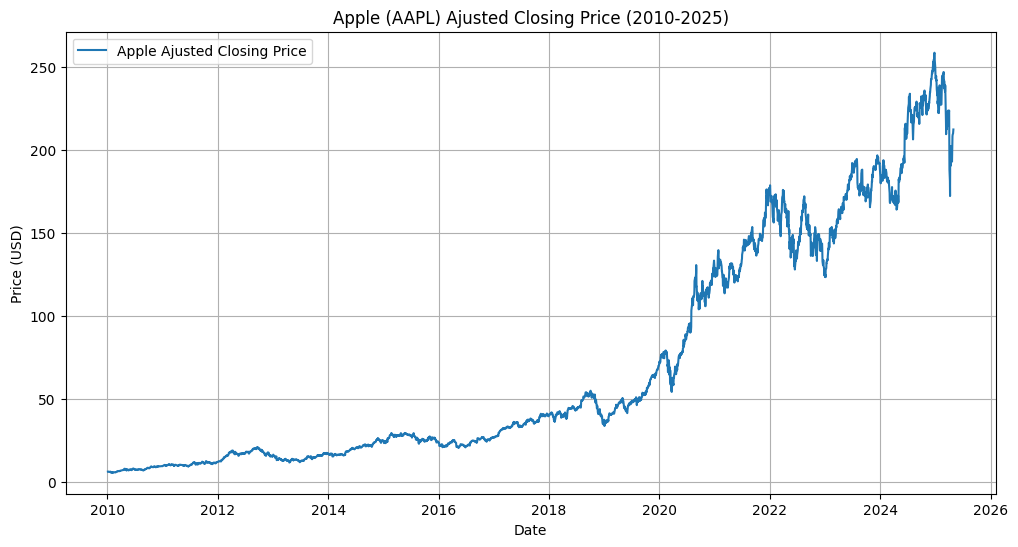

In [29]:
# Problem 5-b

import yfinance as yf
from statsmodels.tsa.stattools import adfuller

# Download Apple (AAPL) stock closing price data from 2010 to 2025
data = yf.download('AAPL', start='2010-01-01', end='2025-05-01', auto_adjust=False)['Adj Close']
prices = data.dropna()

# Print the first 5 rows of closing prices
print("Apple Closing Prices (first 5 rows):")
print(prices.head())

# Perform Augmented Dickey-Fuller test on closing prices
adf_result = adfuller(prices)

# Prepare data for display
results_dict = {
    "ADF Statistic": [adf_result[0]],
    "p-value": [adf_result[1]],
    "Number of Lags Used": [adf_result[2]],
    "Number of Observations Used": [adf_result[3]],
    "Maximized Information Criterion": [adf_result[5]]
}

# Convert critical values dict to DataFrame
crit_values_df = pd.DataFrame(adf_result[4], index=["Critical Value"]).T.reset_index()
crit_values_df.columns = ["Significance Level", "Critical Value"]

# Create main results DataFrame
results_df = pd.DataFrame(results_dict)

print("\nADF Test Summary:\n")
print(results_df.to_string(index=False))

print("\nCritical Values:\n")
print(crit_values_df.to_string(index=False))

# Interpretation
if adf_result[1] < 0.05:
    print("\nConclusion: Reject the null hypothesis. The time series is stationary (no unit root).")
else:
    print("\nConclusion: Fail to reject the null hypothesis. The time series has a unit root and is non-stationary.")

# Plot Apple closing prices
plt.figure(figsize=(12,6))
plt.plot(prices, label='Apple Ajusted Closing Price')
plt.title('Apple (AAPL) Ajusted Closing Price (2010-2025)')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()

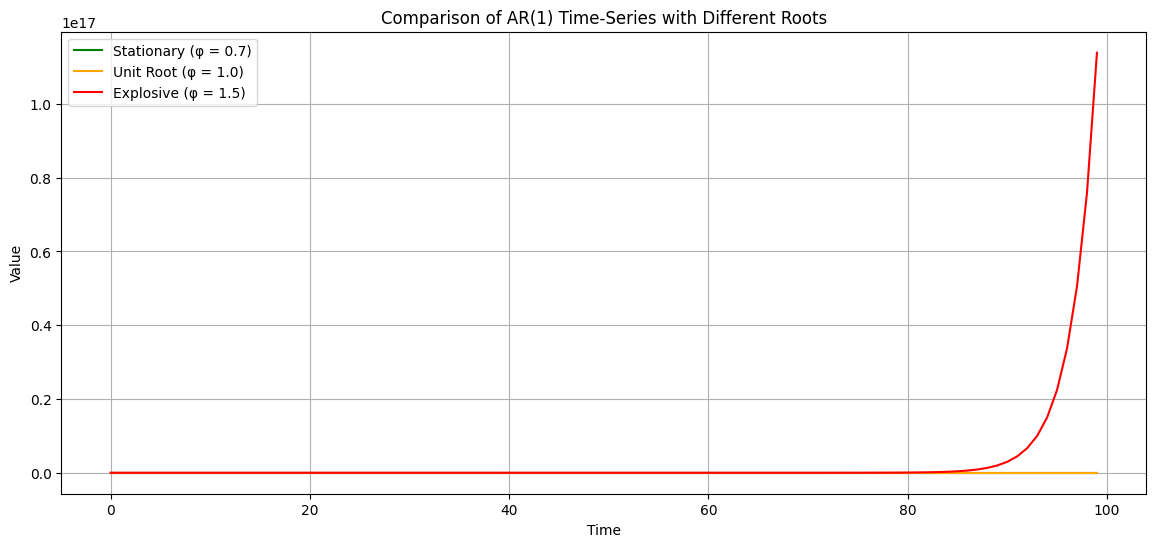

In [30]:
# Problem 5-c: simulations to understand unit root and root 1.5
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
n = 100

def simulate_ar1(phi, n):
    y = np.zeros(n)
    eps = np.random.normal(scale=1, size=n)
    for t in range(1, n):
        y[t] = phi * y[t-1] + eps[t]
    return y

y_stationary = simulate_ar1(0.7, n)
y_unit_root = simulate_ar1(1.0, n)
y_explosive = simulate_ar1(1.5, n)

plt.figure(figsize=(14,6))
plt.plot(y_stationary, label='Stationary (φ = 0.7)', color='green')
plt.plot(y_unit_root, label='Unit Root (φ = 1.0)', color='orange')
plt.plot(y_explosive, label='Explosive (φ = 1.5)', color='red')
plt.title('Comparison of AR(1) Time-Series with Different Roots')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()

In [31]:
# Problem 6:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Generate random data
np.random.seed(0)
t = np.arange(1, 21)
X = np.random.normal(0, 1, size=20)
D = (t > 10).astype(int)  # Dummy variable: 0 if t <= 10, else 1
DX = D * X  # Interaction term

# Create a structural break at t=10
beta1 = 2
beta2 = 5
alpha = 1
epsilon = np.random.normal(0, 1, size=20)

# Build Y with assumption of break structure
Y = alpha + beta1 * X + D * (beta2 - beta1) * X + epsilon

# Build dataframe
df = pd.DataFrame({'Y': Y, 'X': X, 'D': D, 'DX': DX})

# Build regression
model_ols = smf.ols("Y ~ X + DX", data=df).fit()

# Print results
print("=== Regression Model: Y ~ X + DX ===\n")
print(model_ols.summary())

# Interpretation
delta_pval = model_ols.pvalues['DX']
print("\n=== Hypothesis Test ===")
print("Null hypothesis H0: δ = 0 (no structural break in slope)")
print("Alternative hypothesis H1: δ ≠ 0 (structural break in slope)")
print(f"p-value for δ (DX): {delta_pval:.4f}")

if delta_pval < 0.05:
    print("→ Reject H0: Structural break in the slope exists at t = 10.")
else:
    print("→ Fail to reject H0: No significant structural break in the slope.")

=== Regression Model: Y ~ X + DX ===

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.856
Model:                            OLS   Adj. R-squared:                  0.839
Method:                 Least Squares   F-statistic:                     50.49
Date:                Sat, 14 Jun 2025   Prob (F-statistic):           7.05e-08
Time:                        11:28:19   Log-Likelihood:                -31.716
No. Observations:                  20   AIC:                             69.43
Df Residuals:                      17   BIC:                             72.42
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     